# 04 - Reading the results

The same quantities are computed for the test and for the model by `00_processa_resultados.py`. Here we compute them on
a **synthetic** curve (specimen ITA905) to see what each one means.

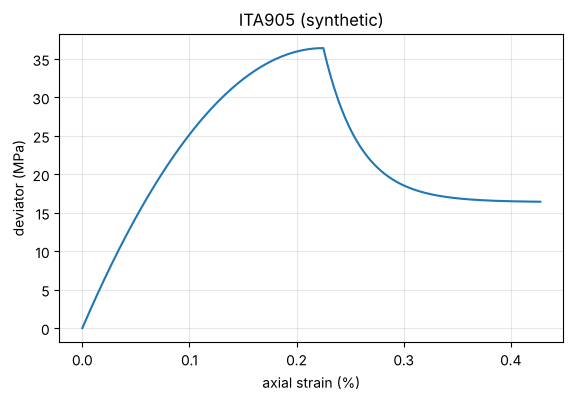

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
syn = Path("..") / "00_Inputs" / "synthetic"
if not (syn / "curves_lab.csv").exists():
    import subprocess, sys
    subprocess.run([sys.executable, "make_synthetic_data.py"], cwd=syn, check=True)
cur = pd.read_csv(syn / "curves_lab.csv"); tg = pd.read_csv(syn / "targets.csv")
sid = "ITA905"
c_ = cur[cur.id_ita == sid]; r = tg[tg.id_ita == sid].iloc[0]
plt.figure(figsize=(6.5, 4)); plt.plot(c_.eps_ax_pct, c_.dev_MPa)
plt.xlabel("axial strain (%)"); plt.ylabel("deviator (MPa)"); plt.title(sid + " (synthetic)"); plt.grid(alpha=.3); plt.show()

## Peak and secant modulus

- **Peak**: maximum deviator.
- **Secant modulus**: slope of the deviator between 40 % and 60 % of the peak, in GPa.

In [2]:
pk = c_.dev_MPa.max()
pre = c_[c_.phase == "pre"]
a = pre[(pre.dev_MPa >= .4*pk) & (pre.dev_MPa <= .6*pk)]
E = np.polyfit(a.eps_ax_pct/100, a.dev_MPa, 1)[0]/1000
print(f"peak = {pk:.1f} MPa;  secant E (40-60 %) = {E:.1f} GPa")

peak = 36.4 MPa;  secant E (40-60 %) = 22.7 GPa


## Equivalent friction after the peak

After the peak the plane has lost its cohesion, so the whole strength is friction. The equivalent friction is
`mu_eq = tau / sn` on the plane at the residual deviator.

In [3]:
dip = r.anisotropy_angle_deg; s3 = r.sigma3_target_MPa
res = c_.dev_MPa.iloc[-1]
th = np.radians(dip)
sn = s3 + res*np.cos(th)**2; tau = res*np.sin(th)*np.cos(th)
print(f"residual deviator = {res:.1f} MPa;  mu_eq = {tau/sn:.2f}  (phi_eq = {np.degrees(np.arctan(tau/sn)):.1f} deg)")

residual deviator = 16.4 MPa;  mu_eq = 0.70  (phi_eq = 34.8 deg)


In the model, `mu_eq` is compared with the input friction `sj_fric`. If it is higher, a part of the plane contacts
is still bonded after the peak or the matrix carries a share of the load. The processing script also exports the number
of bonded plane contacts along the test, which shows this directly.

Comparing the lab and model values of peak, `E` and `mu_eq` is the core of the back-analysis.